<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
UE L2 Projet de Statistique CMI OSIA
</div>

</a>
<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Année 2026-2027
</div>
<div style="color: blue; font-size: 1.5em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Nom : BOSSON  Prénom : Raphael

Nom : PACHER  Prénom : Alexis
</div>


Modèle de compte-rendu du projet avec codes commentés, sorties numériques et graphiques



<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Importation des données
</div>

Le code ci-dessous permet d'importer ces différents fichiers, de visualiser leur contenu ainsi que leur organisation sous forme de DataFrame Pandas.

**Noms et coordonnées des stations**

In [16]:
import pandas as pd

stations_toulouse = pd.read_parquet("stations_toulouse.parquet")

**Données d'entrainement**

``history_toulouse_train`` dans le code ci-dessous est un DataFrame Pandas, avec :
- des lignes identifiées par un MultiIndex (nom de la station et date de mesure)
- des colonnes nommées ``bikes`` et ``stands``qui contiennent respectivement le nombre de vélos disponibles et le nombre de vélos manquants pour une station et une date (jour/heure) données

In [17]:
history_toulouse_train = pd.read_parquet("history_toulouse_train.parquet")

**Données de test**

``history_toulouse_test`` dans le code ci-dessous est un DataFrame Pandas, avec :
- des lignes identifiées par un MultiIndex (une station à la date de la dernière mesure faite dans les données d'entraînement)
- des colonnes nommées ``bikes_+15min``,...,``bikes_+120min`` qui doivent être complétées par des prévisions tous les 15 minutes pendant 2 heures

In [18]:
history_toulouse_test = pd.read_parquet("history_toulouse_test.parquet")

<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Statistique descriptive des données
</div>

Vous devez inclure ici les résultats de statistique descriptive qui vous semblent pertinents pour le problème de prévision du nombre de vélos. Vous devez en particulier répondre aux questions suivantes :

- (a) déterminer le nombre maximal de vélos disponibles par station et afficher sur une carte les stations en fonction d'un code couleur proportionnel à ce nombre
- (b) déterminer s'il existe des valeurs manquantes dans les données
- (c) déterminer les nombres de mesures pour chaque station et afficher un histogramme de leur répartition
- (d) déterminer les dates de début et de fin des mesures par stations, et faire une représentation graphique de leur dispersion
- (e) proposer des statistique de base par station : maximimum, minimum, moyenne, écart-type, quartiles, et en faire une représentation par Boxplot
- (f) calculer la courbe moyenne journalière de remplissage d'une station (toutes les 15 minutes), et de l'ensemble des stations / calculer également la courbe médiane, 1er-quartile, 3-ème quartile
- (g) tracer sur quelques cartes l'évolution temporelle de remplissage moyen de l'ensemble des stations en choisissant quelques moments dans une journée et en déduire des dynamiques urbaines de remplissage en fonction des heures de la journée et de la localisation des stations
- (h) autres idées ?...

**A compléter...**

In [5]:
%pip install matplotlib --break-system-packages


  Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (11.0 MB)
Using cached contourpy-1.4.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (384 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 24.4 MB/s eta 0:00:0000:01
Using cached kiwisolver-1.5.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (1.5 MB)
Usi

In [2]:
import pandas as pd
import numpy as np
import folium
import branca.colormap as cm
import matplotlib.pyplot as plt

history_toulouse_test = pd.read_parquet("history_toulouse_test.parquet")
history_toulouse_train = pd.read_parquet("history_toulouse_train.parquet")
stations_toulouse = pd.read_parquet("stations_toulouse.parquet")

</div>
On importe toutes les bibliothèques utiles ainsi que les fichiers.

In [5]:
# nb_max_bikes by map

maxi = (
    history_toulouse_train
    .groupby(level="station")
    .max()
    .copy()

)


max_bikes = maxi["bikes"]
stations_toulouse["nombre_max_velos"] = (
    stations_toulouse["station"].map(max_bikes)
)
print(stations_toulouse)

                               station  longitude   latitude  station_id  \
0             00001 - POIDS DE L'HUILE   1.445475  43.604190           0   
1                    00002 - LAFAYETTE   1.445306  43.604885           1   
2    00003 - ALSACE - LORRAINE - POMME   1.445454  43.603302           2   
3      00003 - ALSACE-LORRAINE - POMME   1.445454  43.603302           3   
4                        00003 - POMME   1.445454  43.603302           4   
..                                 ...        ...        ...         ...   
858            TOLOSANE - PASTOURELLES   1.477417  43.543115         858   
859               TOLOSANE - POUCIQUOT   1.469875  43.551101         859   
860               TOURNEFEUILLE MAIRIE   1.346042  43.583665         860   
861                VELASQUEZ - TAMARIS   1.390347  43.621004         861   
862                        ZOLA - DALÍ   1.371961  43.644069         862   

     nombre_max_velos  
0                20.0  
1                25.0  
2              

</div>
Ici, on recupère le nombre maximum de vélo par station. Ensuite, on associe le nombre maximum de vélos à la latitude et longitude de leur station.

In [6]:
# Carte centrée sur les stations
m = folium.Map(
    location=[
        stations_toulouse["latitude"].mean(),
        stations_toulouse["longitude"].mean()
    ],
    zoom_start=12
)

# Échelle de couleurs basée sur le nombre maximum de vélos
colormap = cm.LinearColormap(
    colors=["blue", "cyan", "yellow", "orange", "red"],
    vmin=stations_toulouse["nombre_max_velos"].min(),
    vmax=stations_toulouse["nombre_max_velos"].max(),
    caption="Nombre maximum de vélos"
)

# Ajouter les stations
for _, row in stations_toulouse.dropna(
    subset=["nombre_max_velos"]
).iterrows():

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        color=colormap(row["nombre_max_velos"]),
        fill=True,
        fill_color=colormap(row["nombre_max_velos"]),
        fill_opacity=0.8,
        popup=folium.Popup(
            f"""
            <b>Station :</b> {row['station']}<br>
            <b>ID :</b> {row['station_id']}<br>
            <b>Nombre maximum de vélos :</b>
            {row['nombre_max_velos']}
            """,
            max_width=300
        ),
        tooltip=(
            f"{row['station']} : "
            f"{row['nombre_max_velos']} vélos maximum"
        )
    ).add_to(m)

# Ajouter la légende
colormap.add_to(m)

m

</div>
On a maintenant fait apparaitre la carte avec le nombre maximum de vélos par station. On a ajouter une échelle de couleur afin de mieux visualiser où sont majoritairement concentré les vélos.
Ainsi, on peut voir que plus on se rapproche du centre-ville plus le maximum de vélos est important. On en conclue donc que la majorité des vélos sont utilisés pour au centre-ville.

In [7]:
valeurs_manquantes = history_toulouse_train.isna().sum()
valeurs_manquantes

bikes     0
stands    0
dtype: int64

</div>
Il n'y a pas de valeurs manquantes.

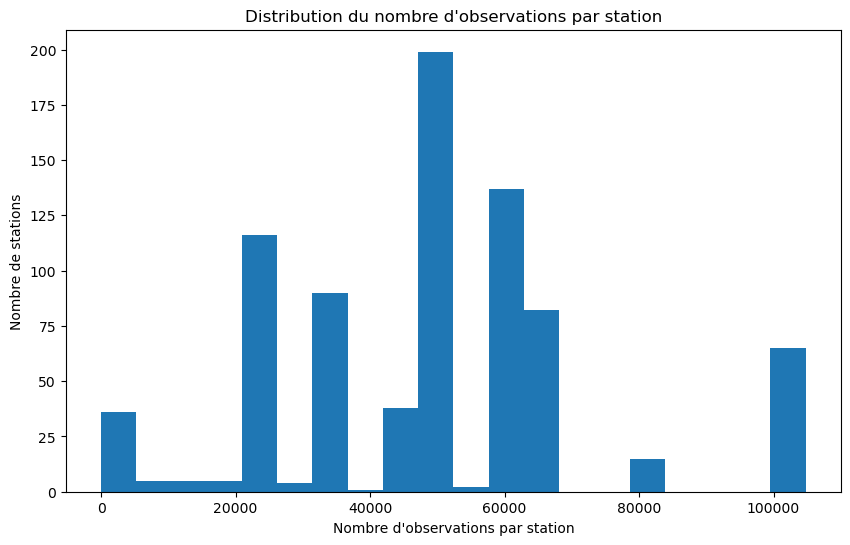

In [8]:
nb_obs = (
    history_toulouse_train
    .groupby(level="station")
    .count()
)
vect_nb_obs = nb_obs["bikes"]

plt.figure(figsize=(10, 6))

plt.hist(vect_nb_obs, bins=20)

plt.xlabel("Nombre d'observations par station")
plt.ylabel("Nombre de stations")
plt.title("Distribution du nombre d'observations par station")

plt.show()

</div>
La majorité des stations ont entre 45 000 et 70 000 mesures.

In [9]:
firstm = (
    history_toulouse_train
    .groupby(level="station")
    .head(1)
    .copy()
)
firstm

,,bikes,stands
station,commit_at,,
00001 - POIDS DE L'HUILE,2023-08-05 12:15:00,10,9
00002 - LAFAYETTE,2023-08-05 12:15:00,24,0
00003 - ALSACE - LORRAINE - POMME,2024-10-31 10:00:00,17,0
00003 - ALSACE-LORRAINE - POMME,2025-11-10 14:30:00,16,1
00003 - POMME,2023-08-05 12:15:00,14,4
...,...,...,...
NARBONNE - CLOTASSES,2025-08-13 14:15:00,0,0
PASTEUR - LAVOISIER,2025-08-04 10:00:00,0,0
PLACE GEORGES BRASSENS,2025-08-05 09:15:00,0,0


In [10]:
lastm = (
    history_toulouse_train
    .groupby(level = "station")
    .tail(1)
    .copy()
)
lastm

,,bikes,stands
station,commit_at,,
00001 - POIDS DE L'HUILE,2026-07-31 21:45:00,9,7
00002 - LAFAYETTE,2026-07-31 23:45:00,9,9
00003 - ALSACE - LORRAINE - POMME,2025-11-10 11:45:00,18,0
00003 - ALSACE-LORRAINE - POMME,2026-07-31 21:45:00,12,4
00003 - POMME,2025-01-05 05:45:00,17,0
...,...,...,...
NARBONNE - CLOTASSES,2025-08-22 19:15:00,0,16
PASTEUR - LAVOISIER,2025-08-05 10:15:00,0,0
PLACE GEORGES BRASSENS,2025-08-05 11:00:00,0,0


In [11]:
donnees_first = firstm.index.get_level_values("commit_at")
donnees_last = lastm.index.get_level_values("commit_at")
station = firstm.index.get_level_values("station")

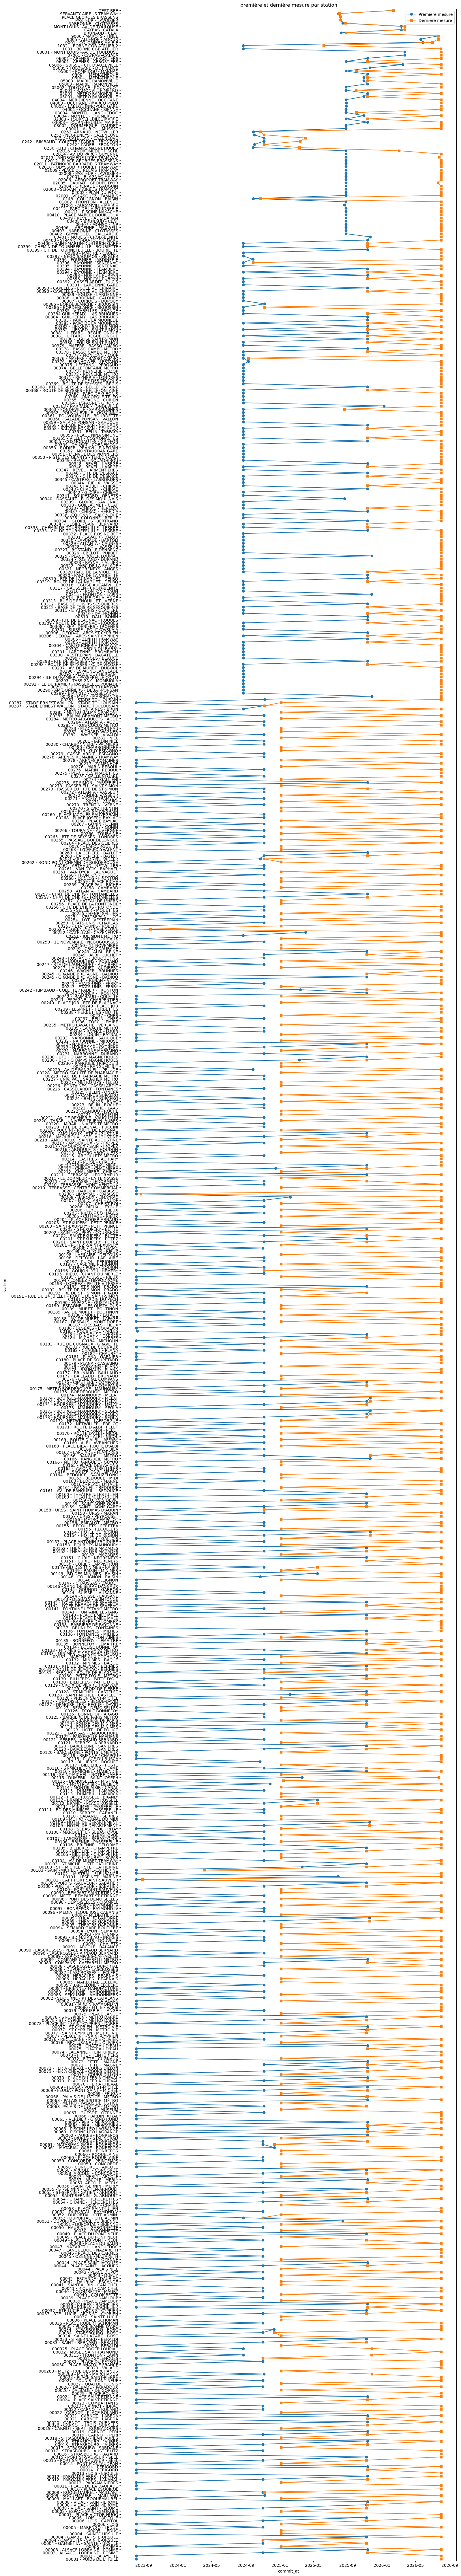

In [12]:
import matplotlib.dates as mdates
from datetime import datetime

plt.figure(figsize=(15, 115))
position = range(len(station))
plt.ylim(position[0] - 0.5,position[-1] + 0.5)
plt.plot(donnees_first, station, marker='o', label='Première mesure')
plt.plot(donnees_last, station, marker='s', label='Dernière mesure')

plt.ylabel('station')
plt.xlabel('commit_at')
plt.title('première et dernière mesure par station')
plt.legend()
plt.show()

</div> 
On constate donc que la majorité des temps d'observations est assez longue (espace entre les points bleu et orange)  sauf pour certaines station comme les 5 dernières.

In [13]:
station = "00001 - POIDS DE L'HUILE"
donnees_station = history_toulouse_train.loc[station]
bikes_station = donnees_station["bikes"]
print("minimum des vélos :",bikes_station.min())
print("maximum des vélos :",bikes_station.max())
print("median des vélos :" ,bikes_station.median())
print("somme total des vélos :",bikes_station.sum())
print("nombre de vélos :",bikes_station.count())
print("moyenne des vélos :",bikes_station.mean())

minimum des vélos : 0
maximum des vélos : 20
median des vélos : 3.0
somme total des vélos : 612978
nombre de vélos : 104775
moyenne des vélos : 5.85042233357194


In [8]:
stations = history_toulouse_train.index.get_level_values("station").unique()[:10]
print(stations)
donnees = history_toulouse_train.loc[history_toulouse_train.index.get_level_values("station").isin(stations)]
print(donnees)
moy = (
    donnees
    .groupby(level=0)["bikes"]
        .mean()
    .copy()
)
moy

Index(['00001 - POIDS DE L'HUILE', '00002 - LAFAYETTE',
       '00003 - ALSACE - LORRAINE - POMME', '00003 - ALSACE-LORRAINE - POMME',
       '00003 - POMME', '00004 - GAMBETTA - SAINTE - URSULE',
       '00004 - GAMBETTA - SAINTE-URSULE', '00004 - GAMBETTA - STE-URSULE',
       '00004 - SAINTE-URSULE', '00005 - LEDUC'],
      dtype='str', name='station')
                                              bikes  stands
station                  commit_at                         
00001 - POIDS DE L'HUILE 2023-08-05 12:15:00     10       9
                         2023-08-05 12:30:00     10       9
                         2023-08-05 12:45:00     10       9
                         2023-08-05 13:00:00     11       8
                         2023-08-05 13:15:00     11       8
...                                             ...     ...
00005 - LEDUC            2025-01-05 04:45:00      2      17
                         2025-01-05 05:00:00      2      17
                         2025-01-05 05:15:

station
00001 - POIDS DE L'HUILE               5.850422
00002 - LAFAYETTE                      9.863566
00003 - ALSACE - LORRAINE - POMME      4.317652
00003 - ALSACE-LORRAINE - POMME        5.815927
00003 - POMME                         10.052652
00004 - GAMBETTA - SAINTE - URSULE     4.861967
00004 - GAMBETTA - SAINTE-URSULE       9.200000
00004 - GAMBETTA - STE-URSULE          6.340913
00004 - SAINTE-URSULE                  6.938091
00005 - LEDUC                          4.882006
Name: bikes, dtype: float64

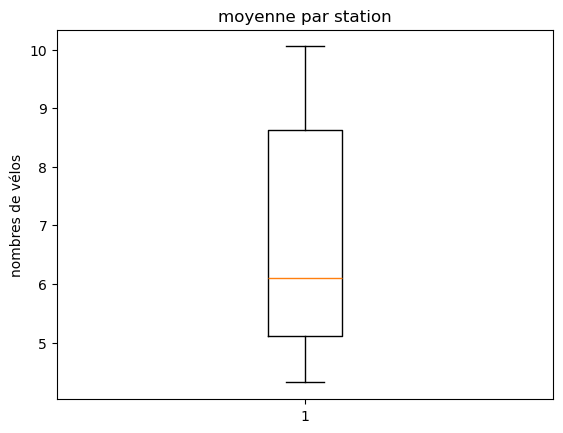

In [15]:
plt.boxplot(moy)
plt.title("moyenne par station")
plt.ylabel("nombres de vélos")
plt.show()

In [16]:
mini = (
    donnees
    .groupby(level=0)["bikes"]
        .min()
    .copy()
)
mini

station
00001 - POIDS DE L'HUILE              0
00002 - LAFAYETTE                     0
00003 - ALSACE - LORRAINE - POMME     0
00003 - ALSACE-LORRAINE - POMME       0
00003 - POMME                         0
00004 - GAMBETTA - SAINTE - URSULE    0
00004 - GAMBETTA - SAINTE-URSULE      7
00004 - GAMBETTA - STE-URSULE         0
00004 - SAINTE-URSULE                 0
00005 - LEDUC                         0
Name: bikes, dtype: uint8

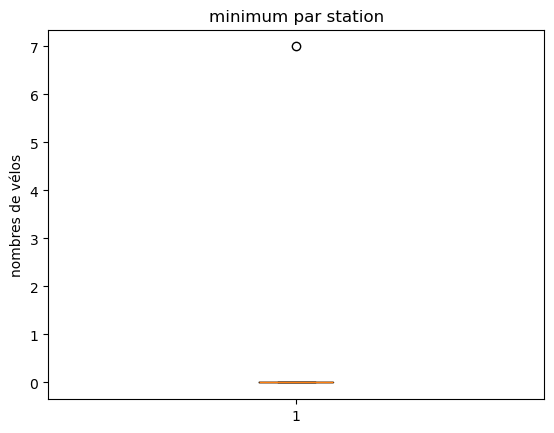

In [17]:
plt.boxplot(mini)
plt.title("minimum par station")
plt.ylabel("nombres de vélos")
plt.show()

In [18]:
maxi = (
    donnees
    .groupby(level=0)["bikes"]
        .max()
    .copy()
)
maxi

station
00001 - POIDS DE L'HUILE              20
00002 - LAFAYETTE                     25
00003 - ALSACE - LORRAINE - POMME     20
00003 - ALSACE-LORRAINE - POMME       19
00003 - POMME                         18
00004 - GAMBETTA - SAINTE - URSULE    20
00004 - GAMBETTA - SAINTE-URSULE      10
00004 - GAMBETTA - STE-URSULE         20
00004 - SAINTE-URSULE                 20
00005 - LEDUC                         19
Name: bikes, dtype: uint8

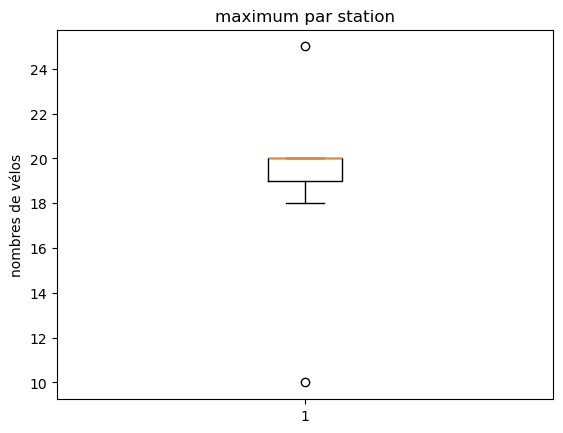

In [19]:
plt.boxplot(maxi)
plt.title("maximum par station")
plt.ylabel("nombres de vélos")
plt.show()

In [20]:
medi = (
    donnees
    .groupby(level=0)["bikes"]
        .median()
    .copy()
)
medi

station
00001 - POIDS DE L'HUILE               3.0
00002 - LAFAYETTE                      7.0
00003 - ALSACE - LORRAINE - POMME      2.0
00003 - ALSACE-LORRAINE - POMME        3.0
00003 - POMME                         12.0
00004 - GAMBETTA - SAINTE - URSULE     2.0
00004 - GAMBETTA - SAINTE-URSULE      10.0
00004 - GAMBETTA - STE-URSULE          3.0
00004 - SAINTE-URSULE                  4.0
00005 - LEDUC                          4.0
Name: bikes, dtype: float64

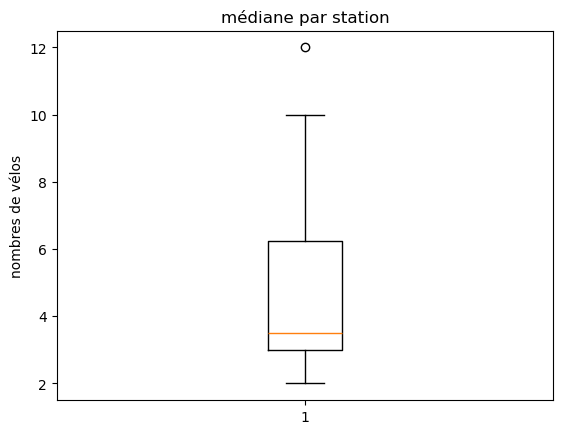

In [21]:
plt.boxplot(medi)
plt.title("médiane par station")
plt.ylabel("nombres de vélos")
plt.show()

In [22]:
nb_v = (
    donnees
    .groupby(level=0)["bikes"]
        .count()
    .copy()
)
nb_v

station
00001 - POIDS DE L'HUILE              104775
00002 - LAFAYETTE                     104783
00003 - ALSACE - LORRAINE - POMME      36008
00003 - ALSACE-LORRAINE - POMME        25278
00003 - POMME                          49799
00004 - GAMBETTA - SAINTE - URSULE     35593
00004 - GAMBETTA - SAINTE-URSULE           5
00004 - GAMBETTA - STE-URSULE          25684
00004 - SAINTE-URSULE                  49799
00005 - LEDUC                          49799
Name: bikes, dtype: int64

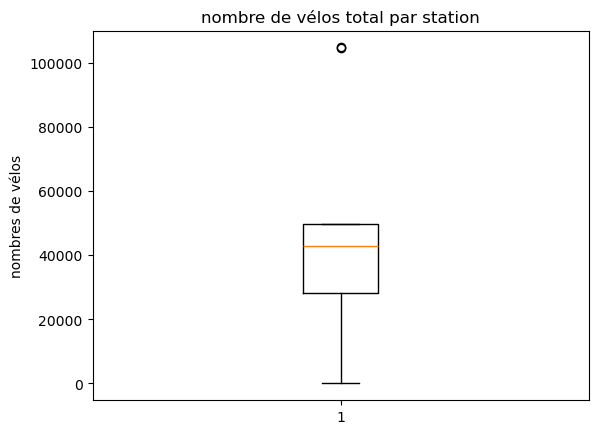

In [23]:
plt.boxplot(nb_v)
plt.title("nombre de vélos total par station")
plt.ylabel("nombres de vélos")
plt.show()

In [24]:
sumv = (
    donnees
    .groupby(level=0)["bikes"]
        .sum()
    .copy()
)
sumv

station
00001 - POIDS DE L'HUILE               612978
00002 - LAFAYETTE                     1033534
00003 - ALSACE - LORRAINE - POMME      155470
00003 - ALSACE-LORRAINE - POMME        147015
00003 - POMME                          500612
00004 - GAMBETTA - SAINTE - URSULE     173052
00004 - GAMBETTA - SAINTE-URSULE           46
00004 - GAMBETTA - STE-URSULE          162860
00004 - SAINTE-URSULE                  345510
00005 - LEDUC                          243119
Name: bikes, dtype: uint64

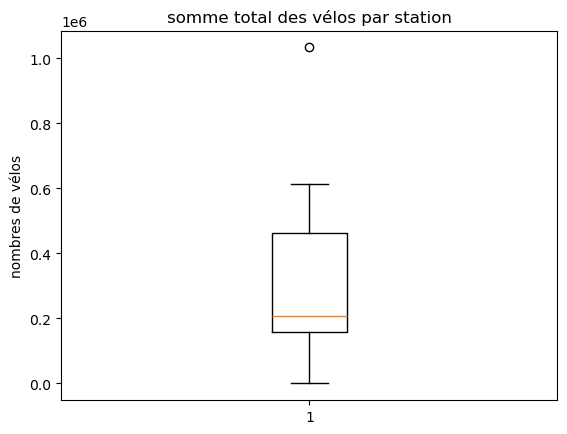

In [25]:
plt.boxplot(sumv)
plt.title("somme total des vélos par station")
plt.ylabel("nombres de vélos")
plt.show()

<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Méthodes de prévision basiques
</div>

Vous devez inclure ici une description des méthodes de bases que vous avez explorées, ainsi qu'une évaluation de leurs performances (cacul de l'erreur RMSE) sur un jeu de données de validation créé à partir de l'ensemble d'apprentissage.

Il est attendu :

- une proposition de 3 méthodes de prévision
- leur classement en terme de performances par calcul de l'erreur RMSE sur l'ensemble de validation
- leurs prévisions sur l'ensemble test à déposer sur Moodle

**Création d'un ensemble de validation**

Le principe de création d'un ensemble de validation est le suivant. Les données disponibles sont partagées en deux sous-ensembles disjoints :

- un ensemble d'apprentissage qui va servir à créer un modèle de prévision
- un ensemble de validation qui va servir à évaluer le modèle de prévision

Il s'agit d'un principe fondamental en apprentissage statistique qui consiste à construire une méthode d'estimation puis **la tester sur un jeu de données qui n'a pas servi à sa construction**.

Dans ce projet, pour créer l'ensemble de validation, on peut simplement retirer les 8 denières mesures dans chaque station de ``history_toulouse_train`` et conserver le reste des données pour l'apprentissage.

In [26]:
# Exemple de création d'un jeu de données d'apprentissage et un jeu de données de validation

# Création ensemble d'apprentissage
# Suppression des 8 dernières mesures de chaque station
rang_depuis_la_fin = (
    history_toulouse_train
    .groupby(level="station")
    .cumcount(ascending=False)
)
rang_depuis_la_fin

station                   commit_at          
00001 - POIDS DE L'HUILE  2023-08-05 12:15:00    104774
                          2023-08-05 12:30:00    104773
                          2023-08-05 12:45:00    104772
                          2023-08-05 13:00:00    104771
                          2023-08-05 13:15:00    104770
                                                  ...  
TEST BEE                  2026-02-12 15:00:00         4
                          2026-02-12 15:15:00         3
                          2026-02-12 15:30:00         2
                          2026-02-12 15:45:00         1
                          2026-02-12 16:00:00         0
Length: 40012622, dtype: int64

In [27]:
history_toulouse_apprentissage = history_toulouse_train[
    rang_depuis_la_fin >= 8
].copy()
history_toulouse_apprentissage

bikes  stands
station                  commit_at                         
00001 - POIDS DE L'HUILE 2023-08-05 12:15:00     10       9
                         2023-08-05 12:30:00     10       9
                         2023-08-05 12:45:00     10       9
                         2023-08-05 13:00:00     11       8
                         2023-08-05 13:15:00     11       8
...                                             ...     ...
TEST BEE                 2026-02-12 13:00:00      0       3
                         2026-02-12 13:15:00      0       3
                         2026-02-12 13:30:00      0       3
                         2026-02-12 13:45:00      0       3
                         2026-02-12 14:00:00      0       3

[40006230 rows x 2 columns]

In [28]:
# Récupèration de la dernière date de mesure pour chaque station
# des données d'apprentissage
last_apprentissage = (
    history_toulouse_apprentissage
    .groupby(level="station")
    .tail(1)
    .copy()
)

last_apprentissage

,,bikes,stands
station,commit_at,,
00001 - POIDS DE L'HUILE,2026-07-31 19:45:00,6,10
00002 - LAFAYETTE,2026-07-31 21:45:00,5,13
00003 - ALSACE - LORRAINE - POMME,2025-11-10 09:45:00,7,11
00003 - ALSACE-LORRAINE - POMME,2026-07-31 19:45:00,15,1
00003 - POMME,2025-01-05 03:45:00,17,0
...,...,...,...
MONT LOUIS –AV. DE TOULOUSE,2026-03-23 18:15:00,10,5
NARBONNE - CLOTASSES,2025-08-22 17:15:00,0,16
PASTEUR - LAVOISIER,2025-08-05 08:15:00,0,0


In [29]:
# Creation de l'ensemble de validation
# On récupère les 9 dernières mesures :
# - la 1ère = dernière mesure dans l'ensemble d'apprentissage
# - les 8 suivantes = valeurs à prédire
last_9 = (
    history_toulouse_train
    .groupby(level="station")
    .tail(9)
    .copy()
)
last_9

bikes  stands
station                  commit_at                         
00001 - POIDS DE L'HUILE 2026-07-31 19:45:00      6      10
                         2026-07-31 20:00:00      1      15
                         2026-07-31 20:15:00      1      15
                         2026-07-31 20:30:00      1      15
                         2026-07-31 20:45:00      1      15
...                                             ...     ...
TEST BEE                 2026-02-12 15:00:00      0       3
                         2026-02-12 15:15:00      0       3
                         2026-02-12 15:30:00      0       3
                         2026-02-12 15:45:00      0       3
                         2026-02-12 16:00:00      0       3

[7189 rows x 2 columns]

In [30]:
# On remet l'index sous forme de colonnes
last_9 = last_9.reset_index()
last_9

,station,commit_at,bikes,stands
0,00001 - POIDS DE L'HUILE,2026-07-31 19:45:00,6,10
1,00001 - POIDS DE L'HUILE,2026-07-31 20:00:00,1,15
2,00001 - POIDS DE L'HUILE,2026-07-31 20:15:00,1,15
3,00001 - POIDS DE L'HUILE,2026-07-31 20:30:00,1,15
4,00001 - POIDS DE L'HUILE,2026-07-31 20:45:00,1,15
...,...,...,...,...
7184,TEST BEE,2026-02-12 15:00:00,0,3
7185,TEST BEE,2026-02-12 15:15:00,0,3
7186,TEST BEE,2026-02-12 15:30:00,0,3
7187,TEST BEE,2026-02-12 15:45:00,0,3


In [31]:
# Numéro de position parmi les 9 dernières mesures
last_9
    

,station,commit_at,bikes,stands
0,00001 - POIDS DE L'HUILE,2026-07-31 19:45:00,6,10
1,00001 - POIDS DE L'HUILE,2026-07-31 20:00:00,1,15
2,00001 - POIDS DE L'HUILE,2026-07-31 20:15:00,1,15
3,00001 - POIDS DE L'HUILE,2026-07-31 20:30:00,1,15
4,00001 - POIDS DE L'HUILE,2026-07-31 20:45:00,1,15
...,...,...,...,...
7184,TEST BEE,2026-02-12 15:00:00,0,3
7185,TEST BEE,2026-02-12 15:15:00,0,3
7186,TEST BEE,2026-02-12 15:30:00,0,3
7187,TEST BEE,2026-02-12 15:45:00,0,3


In [32]:
last_9["horizon"] = (
    last_9.groupby("station").cumcount()
)
last_9

,station,commit_at,bikes,stands,horizon
0,00001 - POIDS DE L'HUILE,2026-07-31 19:45:00,6,10,0
1,00001 - POIDS DE L'HUILE,2026-07-31 20:00:00,1,15,1
2,00001 - POIDS DE L'HUILE,2026-07-31 20:15:00,1,15,2
3,00001 - POIDS DE L'HUILE,2026-07-31 20:30:00,1,15,3
4,00001 - POIDS DE L'HUILE,2026-07-31 20:45:00,1,15,4
...,...,...,...,...,...
7184,TEST BEE,2026-02-12 15:00:00,0,3,4
7185,TEST BEE,2026-02-12 15:15:00,0,3,5
7186,TEST BEE,2026-02-12 15:30:00,0,3,6
7187,TEST BEE,2026-02-12 15:45:00,0,3,7


In [33]:
# Recherche de valeurs manquantes
missing = last_9.loc[
    last_9[['bikes', 'stands']].isna().any(axis=1),TEST BEE 	2026-02-12 15:00:00 	0 	3
7185 	
    ['station', 'commit_at', 'bikes', 'stands']
]

print(missing)

SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (4089152301.py, line 3)

In [ ]:
# On crée une ligne par station et on récupère les 8 valeurs futures
history_toulouse_validation = (
    last_9
    .pivot(
        index="station",
        columns="horizon",
        values="bikes"
    )
    .drop(columns=0)
    .rename(columns={
        1: "bikes_+15min",
        2: "bikes_+30min",
        3: "bikes_+45min",
        4: "bikes_+60min",
        5: "bikes_+75min",
        6: "bikes_+90min",
        7: "bikes_+105min",
        8: "bikes_+120min"
    })
)

# Récupérer la date de la dernière mesure de l'ensemble d'apprentissage par station
cutoff_times = (
    last_9[last_9["horizon"] == 0]
    .set_index("station")["commit_at"]
)

# Ajouter commit_at
history_toulouse_validation["commit_at"] = cutoff_times

# Mettre station + commit_at en MultiIndex
history_toulouse_validation = (
    history_toulouse_validation
    .reset_index()
    .set_index(["station", "commit_at"])
    .sort_index()
)

history_toulouse_validation

**Exemple d'évaluation d'une méthode de prévision**

On donne ci-dessous l'exemple du calcul de l'erreur RMSE sur l'ensemble de validation d'une méthode de base à partir de la moyenne des vélos par station sur l'ensemble d'apprentissage

In [ ]:
# Creation des données à prédire
history_toulouse_basique = history_toulouse_validation.copy()

# Methode de base
mean_bikes_station = (
    history_toulouse_apprentissage
    .groupby(level="station")["bikes"]
    .mean()
    .round()
)

target_columns = [
    "bikes_+15min",
    "bikes_+30min",
    "bikes_+45min",
    "bikes_+60min",
    "bikes_+75min",
    "bikes_+90min",
    "bikes_+105min",
    "bikes_+120min"
]

# Station correspondant à chaque ligne de l'ensemble de validation
stations_a_predire = history_toulouse_basique.index.get_level_values("station")

# Moyenne de chaque station à prédire
predictions = mean_bikes_station.reindex(stations_a_predire)

# Remplissage des 8 horizons avec la même moyenne
history_toulouse_basique.loc[:, target_columns] = (
    predictions.to_numpy()[:, None]
)

In [ ]:
history_toulouse_basique

In [ ]:
history_toulouse_validation

In [ ]:
# Recherche de valeurs manquantes
print("Nombre de valeurs manquantes :", predictions.isna().sum())
print("Valeurs manquantes :", predictions[predictions.isna()])

In [ ]:
# Gestion des valeurs manquantes
stations_problematiques = stations_a_predire[predictions.isna()]
print(stations_problematiques)

In [ ]:
# Nombre d'observations par station
nb_obs = (
    history_toulouse_train
    .groupby(level="station")
    .count()
)
nb_obs

In [ ]:
import numpy as np
np.min(nb_obs)

In [ ]:
print(nb_obs.loc[stations_problematiques])

In [ ]:
vect_nb_obs = nb_obs["bikes"]

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(vect_nb_obs, bins=20)

plt.xlabel("Nombre d'observations par station")
plt.ylabel("Nombre de stations")
plt.title("Distribution du nombre d'observations par station")

plt.show()

In [ ]:
# Stations sans valeurs manquantes
stations_sans_NaN = stations_a_predire[predictions.notna()]
print(stations_sans_NaN)

In [ ]:
import numpy as np

history_toulouse_validation.values

In [ ]:
# Calcul de l'erreur RMSE sur l'ensemble de validation
rmse = np.sqrt((
    (history_toulouse_basique.values- history_toulouse_validation.values)**2
).mean())
print(f'RMSE',rmse)

In [ ]:
# Calcul de l'erreur RMSE sur l'ensemble de validation
rmse = np.sqrt((
    (history_toulouse_basique.loc[stations_sans_NaN].values- history_toulouse_validation.loc[stations_sans_NaN].values)**2
).mean())
print(f'RMSE',rmse)

<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Prévision par apprentissage statistique
</div>

A venir...